# P9: Gradient Descent

**Pass task — FIT1061 Week 10.** Implement gradient descent on 1D and 2D functions. Explore what happens when the landscape is not a simple bowl: local minima trap the algorithm.

> **Milestone task.** P9 requires a tutor discussion for sign-off. After completing all parts, book a discussion with your tutor.

> **P9.1 is personalised by your Monash student ID** — see the 'Your personalised instance' section below.


---

## Setup

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from p9_helpers import (
    # 1D content
    f_quadratic, df_quadratic,
    f_harder, df_harder,
    HAND_TRACE_W0, HAND_TRACE_ALPHA, HAND_TRACE_STEPS,
    plot_function, plot_descent,
    plot_loss_curve, plot_lr_comparison,
    print_trace,
    # 2D content
    f_bowl_2d, grad_bowl_2d, BOWL_MINIMUM_2D, START_POINT_2D,
    HAND_TRACE_2D_START, HAND_TRACE_2D_ALPHA,
    HAND_TRACE_2D_EXPECTED_GRAD, HAND_TRACE_2D_EXPECTED_NEXT,
    f_harder_2d, grad_harder_2d,
    HARDER_2D_GLOBAL_MIN, HARDER_2D_LOCAL_MIN, HARDER_2D_SADDLE,
    plot_contour_2d, plot_contour_with_path_2d,
)
print("Setup OK.")

Setup OK.


---

## Warm-up: the trace from the whiteboard

In the lecture we took **gradient-descent steps by hand** on $f(w) = (w-3)^2$, starting at
$w_0 = 0$ with learning rate $\alpha = 0.1$. Work through it yourself to warm up, then trace 5
steps on your own quadratic in Part 0.

Stuck? This is the exact function we stepped through in the lecture (we did the first three:
$0 \to 0.6 \to 1.08 \to 1.46$); revisit the slides or the workshop.

The derivative is $f'(w) = 2(w-3)$, and the update rule is $w \leftarrow w - \alpha \cdot f'(w)$.
Fill in 5 steps:

| Step | $w$ | $f'(w) = 2(w-3)$ | $w - \alpha f'(w)$ | new $w$ |
|---|---|---|---|---|
| 1 | 0 | -6.0 | 0 - 0.1(-6.0) | 0.6 |
| 2 | 0.6 | -4.8 | 0.6 - 0.1(-4.8) | 1.08 |
| 3 | 1.08 | -3.84 | 1.08 - 0.1(-3.84) | 1.46|
| 4 | 1.46 | -3.07 | 1.464 - 0.1(-3.072) | 1.77 |
| 5 | 1.77 | -2.46 | 1.7712 - 0.1(-2.4576) | 2.02 |

- After 5 steps, is $w$ getting closer to 3 (the minimum)?
yes
*(Same trace as Part 0 below: there you use YOUR personalised minimum $c$ and starting point.)*


---

## Your personalised instance (P9.1)

Your 1D hand-trace quadratic `f(w) = (w - c)^2` and starting point `w_0` are personalised by your Monash student ID. Learning rate $\alpha = 0.1$ and number of steps (5) are the same for everyone.

**Set your Monash student ID below**, then run the next two cells. Do not edit `task_instances.py`.


In [37]:
# Replace the placeholder with your Monash student ID (8 digits).
STUDENT_ID = "36065315"

assert STUDENT_ID.isdigit() and len(STUDENT_ID) == 8, (
    "Set STUDENT_ID to your 8-digit Monash student ID (digits only, in quotes)."
)


In [38]:
# Integrity check + instance generation.
# DO NOT EDIT task_instances.py — your tutor regenerates from your ID
# and compares fingerprints. Modifications will be caught.

from task_instances import generate_instance
from task_instances_lib import fingerprint

instance = generate_instance(STUDENT_ID)
quad = instance["quad"]

print(f"Student ID:                {STUDENT_ID}")
print(f"task_instances.py SHA-256: {fingerprint('task_instances.py')}")
print()
print(quad.describe())


Student ID:                36065315
task_instances.py SHA-256: 48e4c520a1aed302820e76608e3119ff96e8ba5fde38feb80de839e547f45cf7

Personalised quadratic for student 36065315
  function:   f(w) = (w + 1)^2
  derivative: f'(w) = 2 * (w + 1)
  minimum at  w = -1
  start       w_0 = -4
  alpha       = 0.1
  steps       = 5


---

## Part 0: Hand-Trace, Gradient Descent on Paper (P9.1)

Before writing any code, trace the algorithm by hand. **Your quadratic and starting point are personalised** by your Monash student ID. You will trace 5 steps of gradient descent on YOUR function from YOUR starting point.

YOUR function has the form

$$f(w) = (w - c)^2 \qquad f'(w) = 2 (w - c)$$

where $c$ is YOUR personalised minimum location (printed above). With $\alpha = 0.1$, the update rule

$$w \leftarrow w - \alpha \cdot f'(w)$$

shrinks the distance $(w - c)$ by a factor of $0.8$ each step, so the trajectory visibly converges toward $c$ but does not reach it in 5 steps.

> **Different students get different $(c, w_0)$.** Your trace will differ from a peer's. Tutors regenerate from your Monash ID to verify (±0.001 absolute tolerance on the final $w$).

> **You do not need to compute derivatives yourself.** The derivative form is given.


In [39]:
# Hand-trace setup — using YOUR personalised quadratic.
print("YOUR hand-trace setup:")
print(f"  Function:    {quad.f_repr}")
print(f"  Derivative:  {quad.df_repr}")
print(f"  Minimum at:  w = {quad.c}")
print(f"  Start:       w = {quad.w0}")
print(f"  Learning rate: alpha = {quad.alpha}")
print(f"  Steps:       {quad.steps}")
print()
print("Fill in this table by hand:")
print()
print(f"  step | w        | f(w)     | f'(w)    | update    | new w")
print(f"  {'-'*60}")
print(f"  0    | {quad.w0:+.2f}    |  ____    |  ____    |  ____     |  ____")
print(f"  1    |  ____    |  ____    |  ____    |  ____     |  ____")
print(f"  ...  | ...      | ...      | ...      | ...       | ...")


YOUR hand-trace setup:
  Function:    f(w) = (w + 1)^2
  Derivative:  f'(w) = 2 * (w + 1)
  Minimum at:  w = -1
  Start:       w = -4
  Learning rate: alpha = 0.1
  Steps:       5

Fill in this table by hand:

  step | w        | f(w)     | f'(w)    | update    | new w
  ------------------------------------------------------------
  0    | -4.00    |  ____    |  ____    |  ____     |  ____
  1    |  ____    |  ____    |  ____    |  ____     |  ____
  ...  | ...      | ...      | ...      | ...       | ...


### Check your hand trace

After filling in the table on paper, answer these questions:

1. **Does $w$ get closer to YOUR minimum $c$ with every step?** It should: gradient descent moves toward the minimum.
2. **Does the update get smaller each step?** It should: the slope is gentler near the minimum.
3. **After 5 steps, is $w$ close to $c$?** Not exactly: five steps with $\alpha = 0.1$ doesn't fully converge. You should still be a fraction of the way away (the distance shrinks by factor 0.8 each step, so $0.8^5 \approx 0.33$ of the original distance remains).


---

### Articulation (P9.1, graded with the photo)

Compute the 5 steps by hand for YOUR quadratic. Show the table from the cell above filled in completely. Then fill in the answer cell below.


In [40]:
# Articulation answers — type your hand-computed values here.
# Reference YOUR (c, w_0) printed above.

answers = {
    "c": -1,                    # int (YOUR minimum location)
    "w_0": -4,                  # int (YOUR starting point)
    "w_1": -3.4000,             # float, 4 dp
    "w_2": -2.9200,             # float, 4 dp
    "w_3": -2.5360,             # float, 4 dp
    "w_4": -2.2288,             # float, 4 dp
    "w_5": -1.9830,             # float, 4 dp (the FINAL w after 5 steps)
}

# Brief explanation (2-3 sentences) — describe how the distance from c shrinks,
# and whether you'd expect to reach c exactly in 5 steps. Reference YOUR numbers:
explanation = (
    "As mentioned, with an alpha of 0.1, the distance from c shrinks by 0.8 each iteration." \
    "Because of this rate of shrinkage, we will not reach c exactly in 5 steps, but we will get closer to it"
    "as evident by reaching -1.9830 after 5 steps."
)

for k, v in answers.items():
    assert v is not None, f"answers['{k}'] is still None"
assert explanation.strip() != "TYPE YOUR EXPLANATION HERE.", "Write your explanation."
print("Filled in. Photograph hand-trace table + this cell for P9.1.")


Filled in. Photograph hand-trace table + this cell for P9.1.


---

## Part 1: Explore the Loss Function

Let's visualise what gradient descent will be working with.

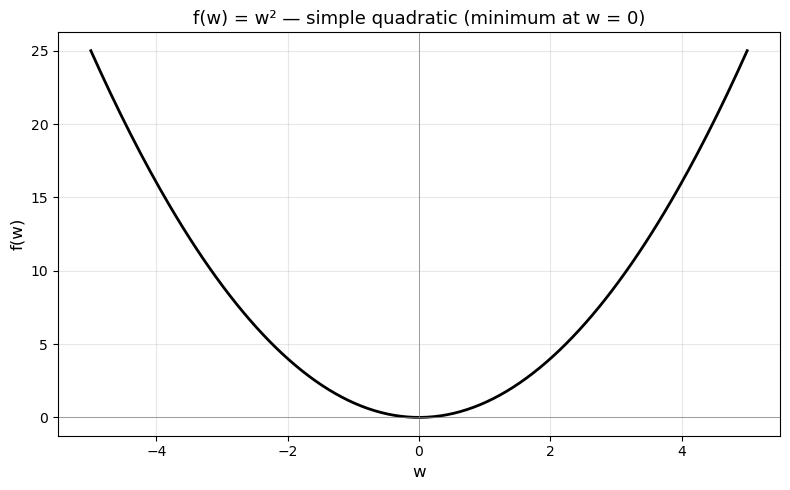

This is the simplest loss function: a parabola with one clear minimum.
Gradient descent should have no trouble finding it.


In [41]:
# The quadratic: f(w) = w^2
plot_function(f_quadratic, w_range=(-5, 5),
              title="f(w) = w² — simple quadratic (minimum at w = 0)")

print("This is the simplest loss function: a parabola with one clear minimum.")
print("Gradient descent should have no trouble finding it.")

---

## Part 2: Implement Gradient Descent (P9.2)

Now implement what you did by hand. The function takes a derivative function, a starting point, a learning rate, and a number of steps, and returns the full trajectory.

In [42]:
def gradient_descent(df, f, w, alpha, steps):
    """Run gradient descent on a 1D function.

    Args:
        df: The derivative function (takes w, returns f'(w)).
        f: The loss function (takes w, returns f(w)).
        w: Starting value (float).
        alpha: Learning rate (float).
        steps: Number of iterations (int).

    Returns:
        A list of (w, f(w)) tuples — the trajectory from start to end.
    """
    # --- YOUR CODE HERE ---
    # Return the trajectory: a list of (w, f(w)) pairs, one per step, starting
    # from the initial point and stepping downhill by the learning rate times
    # the gradient.
    history = [(w, f(w))]
    for n in range(steps):
        # Update rule: w <- w - alpha * f'(w)
        w = w - alpha * df(w)
        history.append((w, f(w)))
        
    return history
    # --- END YOUR CODE ---


# Test on your hand-trace function
history = gradient_descent(df_quadratic, f_quadratic,
                           w=HAND_TRACE_W0, alpha=HAND_TRACE_ALPHA,
                           steps=HAND_TRACE_STEPS)

print("Your gradient descent output:")
print_trace(history)
print()
print(f"After {HAND_TRACE_STEPS} steps: w = {history[-1][0]:.4f}, f(w) = {history[-1][1]:.4f}")
print(f"Expected:          w ≈ 1.3107, f(w) ≈ 1.7180")
print(f"Match: {'Yes' if abs(history[-1][0] - 1.3107) < 0.01 else 'No — check your code'}")

Your gradient descent output:
Step           w        f(w)
------------------------------
   0      4.0000     16.0000
   1      3.2000     10.2400
   2      2.5600      6.5536
   3      2.0480      4.1943
   4      1.6384      2.6844
   5      1.3107      1.7180

After 5 steps: w = 1.3107, f(w) = 1.7180
Expected:          w ≈ 1.3107, f(w) ≈ 1.7180
Match: Yes


**Check on YOUR quadratic.** After implementing `gradient_descent`, the cell below runs it on YOUR personalised $(f, f', w_0, \alpha, \text{steps}=5)$. The final $w$ should match the last row of your hand-trace table (±0.001).

Now run it for more steps and observe convergence.


In [43]:
# Personalised verification: run YOUR gradient_descent on YOUR quadratic.
# Should reproduce the 5-step trajectory you computed by hand (±0.001 on final w).
my_f = lambda w: (w - quad.c) ** 2
my_df = lambda w: 2.0 * (w - quad.c)
my_history = gradient_descent(my_df, my_f, w=float(quad.w0),
                              alpha=quad.alpha, steps=quad.steps)
print(f"YOUR personalised 5-step trajectory (c={quad.c}, w_0={quad.w0}):")
for i, (w, fw) in enumerate(my_history):
    print(f"  step {i}: w = {w:+.4f}, f(w) = {fw:+.4f}")
print()
final_w = my_history[-1][0]
print(f"Final w = {final_w:+.4f}  (should match your hand trace ±0.001)")


YOUR personalised 5-step trajectory (c=-1, w_0=-4):
  step 0: w = -4.0000, f(w) = +9.0000
  step 1: w = -3.4000, f(w) = +5.7600
  step 2: w = -2.9200, f(w) = +3.6864
  step 3: w = -2.5360, f(w) = +2.3593
  step 4: w = -2.2288, f(w) = +1.5099
  step 5: w = -1.9830, f(w) = +0.9664

Final w = -1.9830  (should match your hand trace ±0.001)


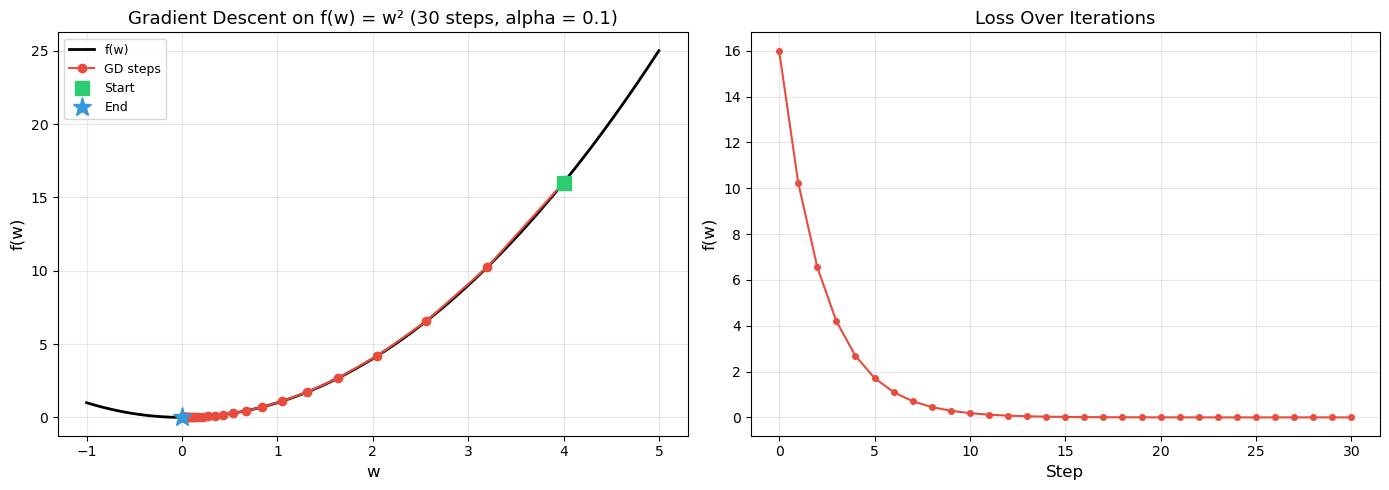

Start: w = 4.0000, f(w) = 16.0000
End:   w = 0.0050, f(w) = 0.0000
Steps: 30


In [44]:
# Run for 30 steps — should get very close to w = 0
history_30 = gradient_descent(df_quadratic, f_quadratic,
                              w=4.0, alpha=0.1, steps=30)

plot_descent(f_quadratic, history_30, w_range=(-1, 5),
             title="Gradient Descent on f(w) = w² (30 steps, alpha = 0.1)")

---

## Part 3: Pick the right learning rate

The learning rate $\alpha$ controls how big a step gradient descent takes. Too small → it takes forever to reach the minimum. Too large → it overshoots and may diverge.

Run the sweep below to compare three learning rates side by side on $f(w) = w^2$, starting at $w = 4$ for 30 steps.

   alpha     final w    final f(w)  outcome
------------------------------------------------------------
    0.01      2.1819        4.7609  too small (alpha = 0.01)
    0.10      0.0050        0.0000  just right (alpha = 0.1)
    0.95      0.1696        0.0288  too large (alpha = 0.95)


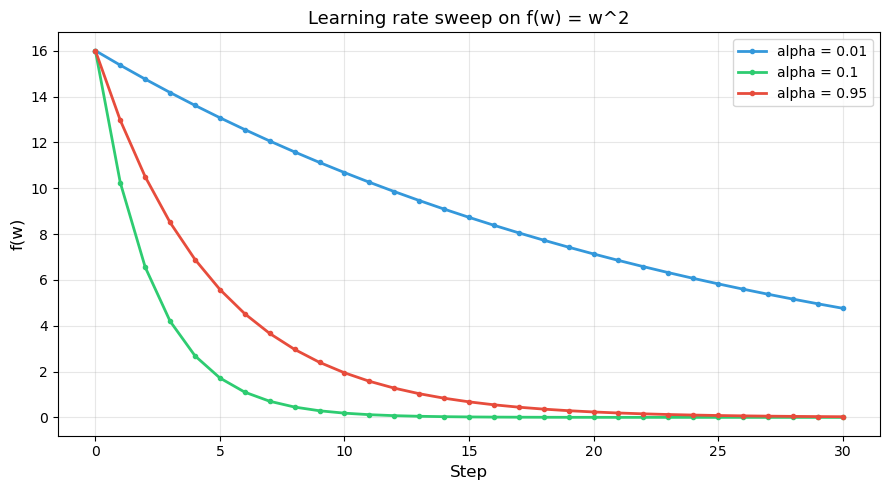


First 6 steps with alpha = 0.95:
Step           w        f(w)
------------------------------
   0      4.0000     16.0000
   1     -3.6000     12.9600
   2      3.2400     10.4976
   3     -2.9160      8.5031
   4      2.6244      6.8875
   5     -2.3620      5.5789
  ... (24 more steps)
  30      0.1696      0.0288


In [45]:
# Run gradient_descent at three learning rates and compare.
alphas = [0.01, 0.1, 0.95]
labels = ["too small (alpha = 0.01)", "just right (alpha = 0.1)", "too large (alpha = 0.95)"]
histories = [
    gradient_descent(df_quadratic, f_quadratic, w=4.0, alpha=a, steps=30)
    for a in alphas
]

# Print final loss for each
print(f"{'alpha':>8s}  {'final w':>10s}  {'final f(w)':>12s}  outcome")
print("-" * 60)
for a, h, lab in zip(alphas, histories, labels):
    w_end, f_end = h[-1]
    print(f"{a:>8.2f}  {w_end:>10.4f}  {f_end:>12.4f}  {lab}")

# Compare loss curves
plot_lr_comparison(f_quadratic, histories, alphas,
                   title="Learning rate sweep on f(w) = w^2")

# Look at the divergent run step by step
print("\nFirst 6 steps with alpha = 0.95:")
print_trace(histories[2], max_rows=6)

### Analysis (P9.3)

1. The "too small" run barely moves. After 30 steps it has dropped how much of the way from $w=4$ to $w=0$?
2. The "too large" run does something dramatic. What is it doing on each step, and why?
3. If you had to choose a single learning rate without running an experiment, what would you base your guess on? (Hint: the answer depends on the *shape* of the function (its curvature).)

1. The "too small" run a = 0.01 barely moves. After 30 steps, it is down to w=2.18 which is about 45% of the distance to the minimum at w=0.
2. The "too large" run a = 0.95 is well over the minimum on each step. In a large bowl, due to its size, the update will bounce up and down, back and forth and while it does eventually converge reaching w = 0.1696, it does so in 30 steps.
3. If I knew nothing about the function, and had to guess a learning rate, I'd use the curvature (2nd derivative) of the function. When the function is a steep narrow bowl, the learning rate is so large that it will violently overshoot so a very small alpha is required. If it is a wide shallow bowl, a small alpha will need thousands of steps to converge, so a larger value of alpha is safe.
_Your answer here._

---

## Part 4: A harder landscape: local minima

Your `gradient_descent` function works on *any* differentiable function. The helpers provide a harder one:

$$f(w) = (w - 3)^2 + 0.5\sin(4w)$$

This has a bowl shape centred near $w = 3$, but with ripples from the sine term. The ripples create **local minima**: points where the gradient is zero but the function is not at its lowest value.

Run gradient descent from three different starting points and see whether you converge to the global minimum (near $w = 3$) or to one of the local minima.

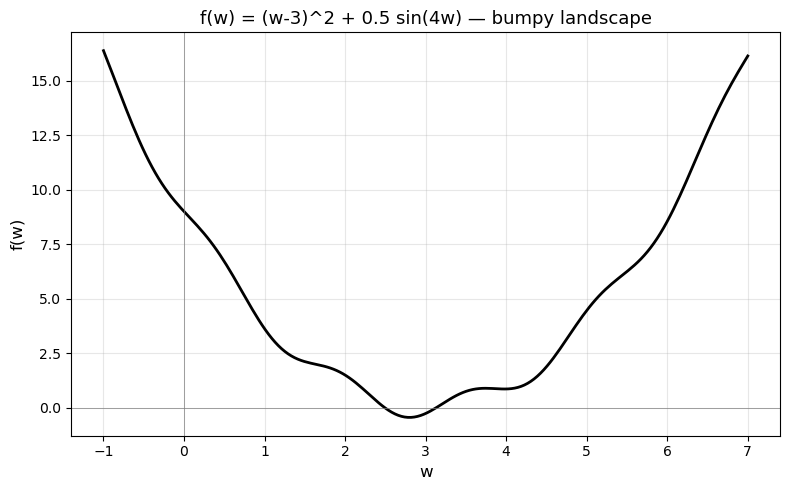

 start w       end w    end f(w)
-----------------------------------
   -1.00      2.7994     -0.4496
    0.00      2.7994     -0.4496
    5.00      3.9787      0.8552


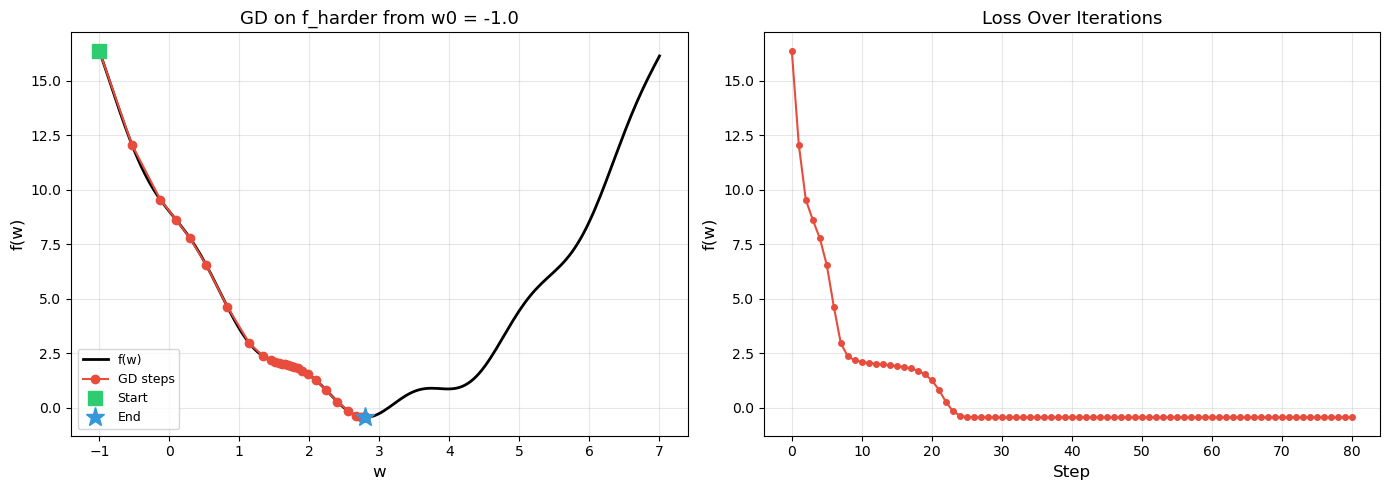

Start: w = -1.0000, f(w) = 16.3784
End:   w = 2.7994, f(w) = -0.4496
Steps: 80


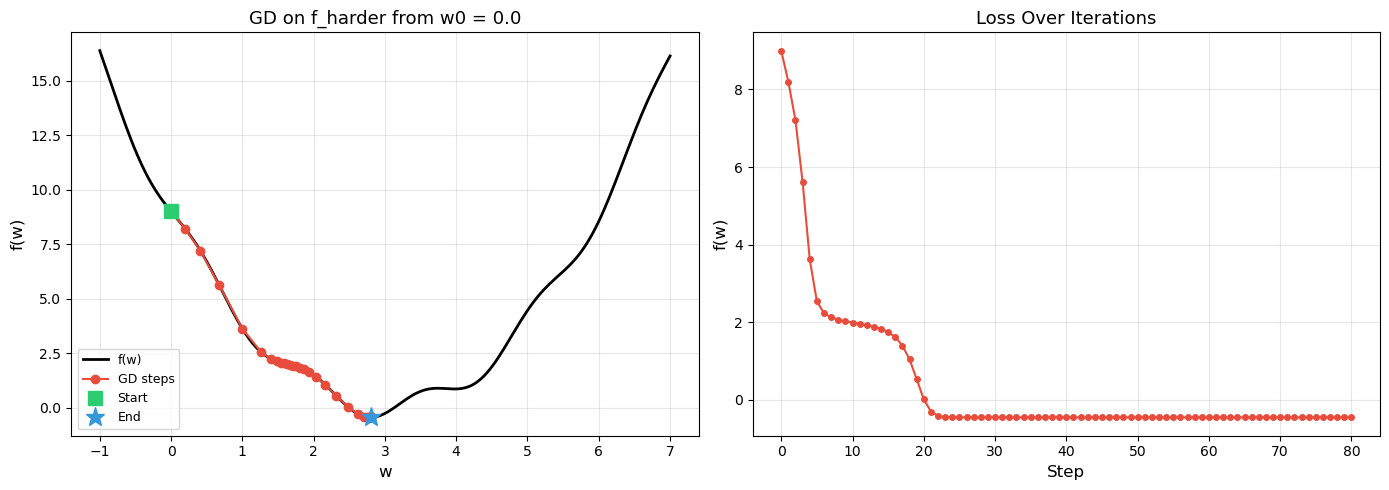

Start: w = 0.0000, f(w) = 9.0000
End:   w = 2.7994, f(w) = -0.4496
Steps: 80


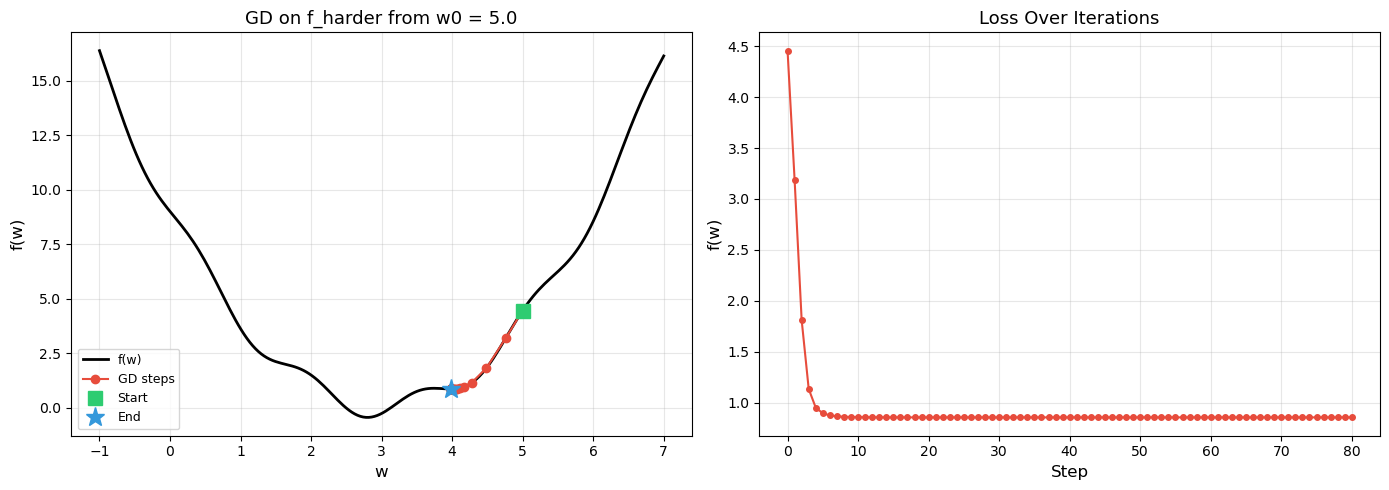

Start: w = 5.0000, f(w) = 4.4565
End:   w = 3.9787, f(w) = 0.8552
Steps: 80


In [46]:
# Visualise the harder function so you can see the local minima.
plot_function(f_harder, w_range=(-1, 7),
              title="f(w) = (w-3)^2 + 0.5 sin(4w) — bumpy landscape")

# Run gradient descent from three different starting points
starts = [-1.0, 0.0, 5.0]
histories_harder = [
    gradient_descent(df_harder, f_harder, w=w0, alpha=0.05, steps=80)
    for w0 in starts
]

print(f"{'start w':>8s}  {'end w':>10s}  {'end f(w)':>10s}")
print("-" * 35)
for w0, h in zip(starts, histories_harder):
    print(f"{w0:>8.2f}  {h[-1][0]:>10.4f}  {h[-1][1]:>10.4f}")

# Show each descent path
for w0, h in zip(starts, histories_harder):
    plot_descent(f_harder, h, w_range=(-1, 7),
                 title=f"GD on f_harder from w0 = {w0}")

### Local minima reflection (P9.4)

Look at the three end points above and the three descent plots.

1. Which starting point reached the **global minimum** (the lowest value of $f$)?
2. Which starting points got stuck at a **local minimum**?
3. **Why** does gradient descent get stuck? What is the gradient doing at a local minimum? (Hint: think about the *slope* of $f$ at the point where the algorithm stops.)
4. If you only had your end value of $f(w)$ and not the plot, how would you know whether you had found the global minimum?

1. w=-1 and w=0
2. w=5
3. Similar to the restrictions of some search algorithms we learned. gradient descent gets trapped in local minima. It only looks at its direct neighbors (slope values) and because its a local minimum both sides are a higher f'(x). Because the formula multiplies the slope value, the updated product also becomes 0 and the algorithm halts, even though its not the actual miminum point furhtest down.
4. I would not. If the slope value became 0, there's no way to know if there exists another stationary point anywhere else.

> **This is the central limitation of gradient descent.** It is a *local* algorithm: it always moves downhill from where it is. If you start in the wrong basin, you stay there. In real ML systems with millions of parameters, you cannot visualise the landscape; you can only watch your loss curve. The shape of the loss curve, alone, does not tell you whether you are at the global minimum.

---

## Part 5: From 1D to 2D: the gradient as a vector (P9.5)

In Parts 2–4 you minimised functions of one variable using the update rule

$$w \leftarrow w - \alpha \cdot f'(w)$$

Real machine-learning models have many parameters: a neural network might have millions of weights, all adjusted simultaneously. The jump from one dimension to two is where the concept clicks: instead of a single slope, you follow a **gradient**: a vector that points in the direction of steepest ascent. To minimise, you walk the opposite way.

For a 2D function $f(x_1, x_2)$, the gradient is

$$\nabla f = \left[ \frac{\partial f}{\partial x_1}, \frac{\partial f}{\partial x_2} \right]$$

and the update becomes

$$\mathbf{x} \leftarrow \mathbf{x} - \alpha \nabla f(\mathbf{x})$$

A **partial derivative** is the same operation you already know: differentiate with respect to one variable, treating the other as a constant. For the bowl $f(x_1, x_2) = (x_1 - 2)^2 + (x_2 - 1)^2$:

- $\partial f / \partial x_1 = 2(x_1 - 2)$ (differentiate, treating $x_2$ as constant).
- $\partial f / \partial x_2 = 2(x_2 - 1)$

In [47]:
# Hand-trace check — fill in your work on paper first, then run this cell to compare.
print("Hand-trace setup for 2D:")
print(f"  Function:       f(x1, x2) = (x1 - 2)^2 + (x2 - 1)^2")
print(f"  Starting point: x = {HAND_TRACE_2D_START}")
print(f"  Learning rate:  alpha = {HAND_TRACE_2D_ALPHA}")
print()
print("On paper, compute:")
print("  1. df/dx1 at x = (-3, -2)")
print("  2. df/dx2 at x = (-3, -2)")
print("  3. The gradient vector [df/dx1, df/dx2]")
print("  4. The new position after one step: x_new = x - alpha * gradient")
print()
print("Expected results (don't peek until you've tried it):")
print(f"  Gradient at start: {HAND_TRACE_2D_EXPECTED_GRAD}")
print(f"  New position:      {HAND_TRACE_2D_EXPECTED_NEXT}")
print(f"  Loss at new pos:   {f_bowl_2d(HAND_TRACE_2D_EXPECTED_NEXT):.4f}  "
      f"(was {f_bowl_2d(HAND_TRACE_2D_START):.4f})")

Hand-trace setup for 2D:
  Function:       f(x1, x2) = (x1 - 2)^2 + (x2 - 1)^2
  Starting point: x = [-3. -2.]
  Learning rate:  alpha = 0.1

On paper, compute:
  1. df/dx1 at x = (-3, -2)
  2. df/dx2 at x = (-3, -2)
  3. The gradient vector [df/dx1, df/dx2]
  4. The new position after one step: x_new = x - alpha * gradient

Expected results (don't peek until you've tried it):
  Gradient at start: [-10.  -6.]
  New position:      [-2.  -1.4]
  Loss at new pos:   21.7600  (was 34.0000)


### Implement `gradient_descent_2d`

Now translate your 1D implementation to 2D. The structure is identical; the only changes are:

- `w` becomes `x`, a NumPy array of shape (2,), not a scalar.
- `df` returns a NumPy array of shape (2,), not a scalar.
- The update `x = x - alpha * grad_f(x)` is element-wise NumPy arithmetic.
- The trajectory stores arrays: you must `.copy()` each `x` before appending or you will get a list of aliases pointing to the *same* mutated array.

In [48]:
def gradient_descent_2d(grad_f, x0, alpha, steps):
    """Run 2D gradient descent on a differentiable function.

    Args:
        grad_f: Gradient function. Takes a (2,) array and returns a (2,) array.
        x0:     Starting point as a (2,) NumPy array (or list of length 2).
        alpha:  Learning rate (scalar).
        steps:  Number of iterations.

    Returns:
        A list of (2,) NumPy arrays — the trajectory including the starting
        point. Length = steps + 1.
    """
    # --- YOUR CODE HERE ---
    # Return the trajectory: a list of the successive x positions, one per step,
    # starting from the initial point and stepping downhill by the learning rate
    # times the gradient.
    x = np.array(x0, dtype=float)
    path = [x]
    for n in range(steps):
        x = x - alpha * grad_f(x)
        path.append(x)
        
    return path
    # --- END YOUR CODE ---


# Verify on the bowl: starting at (-3, -2) with alpha = 0.1, after 40 steps
# you should converge near (2, 1).
path_bowl = gradient_descent_2d(grad_bowl_2d,
                                x0=START_POINT_2D,
                                alpha=0.1, steps=40)

print(f"{'Step':>4}  {'x1':>10}  {'x2':>10}  {'f(x)':>10}")
print("-" * 42)
for i, x in enumerate(path_bowl[:6]):
    print(f"{i:4d}  {x[0]:10.4f}  {x[1]:10.4f}  {f_bowl_2d(x):10.4f}")
print("...")
last = path_bowl[-1]
print(f"{len(path_bowl)-1:4d}  {last[0]:10.4f}  {last[1]:10.4f}  "
      f"{f_bowl_2d(last):10.4f}")
print(f"\nConverged to: {last}  (target: {BOWL_MINIMUM_2D})")

Step          x1          x2        f(x)
------------------------------------------
   0     -3.0000     -2.0000     34.0000
   1     -2.0000     -1.4000     21.7600
   2     -1.2000     -0.9200     13.9264
   3     -0.5600     -0.5360      8.9129
   4     -0.0480     -0.2288      5.7043
   5      0.3616      0.0170      3.6507
...
  40      1.9993      0.9996      0.0000

Converged to: [1.99933539 0.99960123]  (target: [2. 1.])


### Hints (open only if stuck)

<details>
<summary><b>Hint 1:</b> Same shape as the 1D loop</summary>

Your 1D `gradient_descent` had this shape:

```
history = [(w, f(w))]
for _ in range(steps):
    w = w - alpha * df(w)
    history.append((w, f(w)))
return history
```

Your 2D version has the same shape. The only differences are:
- `w` becomes `x`, a (2,) array.
- `df(w)` becomes `grad_f(x)`, returning a (2,) array.
- You return just the trajectory of `x` values, not `(w, f(w))` tuples.
</details>

<details>
<summary><b>Hint 2:</b> NumPy update is element-wise</summary>

```python
x = x - alpha * grad_f(x)
```
This works element-wise on the (2,) array; no explicit loop over coordinates is needed.
</details>

<details>
<summary><b>Hint 3:</b> The aliasing trap (read this one even if you are not stuck)</summary>

NumPy arrays are mutable. If you write `path.append(x)` instead of `path.append(x.copy())`, every entry in `path` will end up pointing at the *same* array, and once the loop finishes, every entry shows the final value. Print `path[0]` after the loop: if it does not equal your starting point, this is the bug.
</details>

> **No full-skeleton hint.** Same discipline as P2 and P3: translate the lecture pseudocode into Python yourself. The milestone discussion will probe whether you wrote the body.

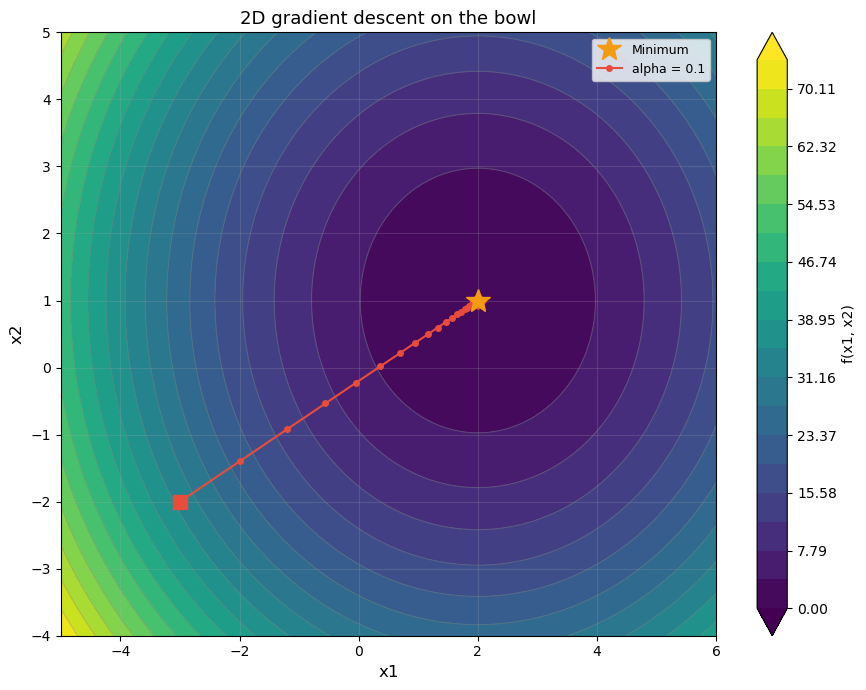

In [49]:
# Visualise the trajectory on a contour plot.
plot_contour_with_path_2d(
    f_bowl_2d,
    paths=[path_bowl],
    labels=["alpha = 0.1"],
    title="2D gradient descent on the bowl",
    minimum=BOWL_MINIMUM_2D
)

---

## Part 6: A 2D non-convex landscape

Part 4 showed that 1D gradient descent gets stuck at local minima. The same is true in 2D, and now there are multiple *basins of attraction*, regions of starting points that all flow to the same minimum.

The helper provides a 2D function with two minima:

$$f(x_1, x_2) = 0.1(x_1^2 + x_2^2) - 3 \exp\!\big(-((x_1 - 2)^2 + (x_2 - 1)^2)\big) - 1.5 \exp\!\big(-((x_1 + 2)^2 + (x_2 + 1)^2)\big)$$

The **global minimum** is in the deeper well near $(2, 1)$. There is also a **local minimum** in the shallower well near $(-2, -1)$. Where you end up depends on where you start.

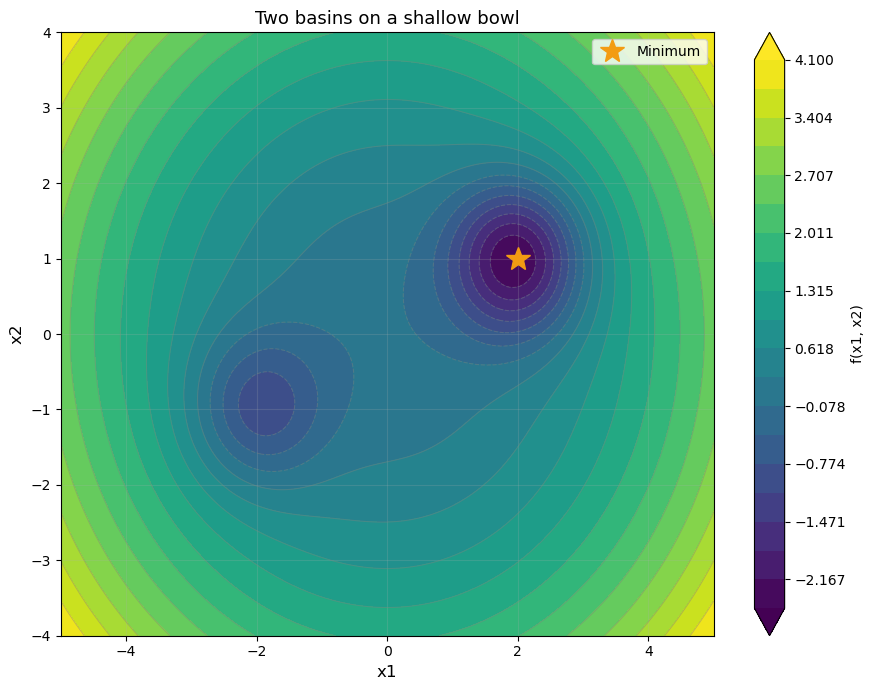

           start  →               end      f(end)  basin
-----------------------------------------------------------------
  (+3.00, +2.00)     (+1.935, +0.968)      -2.516  GLOBAL
  (+0.50, +0.50)     (+1.935, +0.968)      -2.516  GLOBAL
  (-0.50, -0.50)     (-1.873, -0.936)      -1.032  local
  (-3.00, -2.00)     (-1.873, -0.936)      -1.032  local


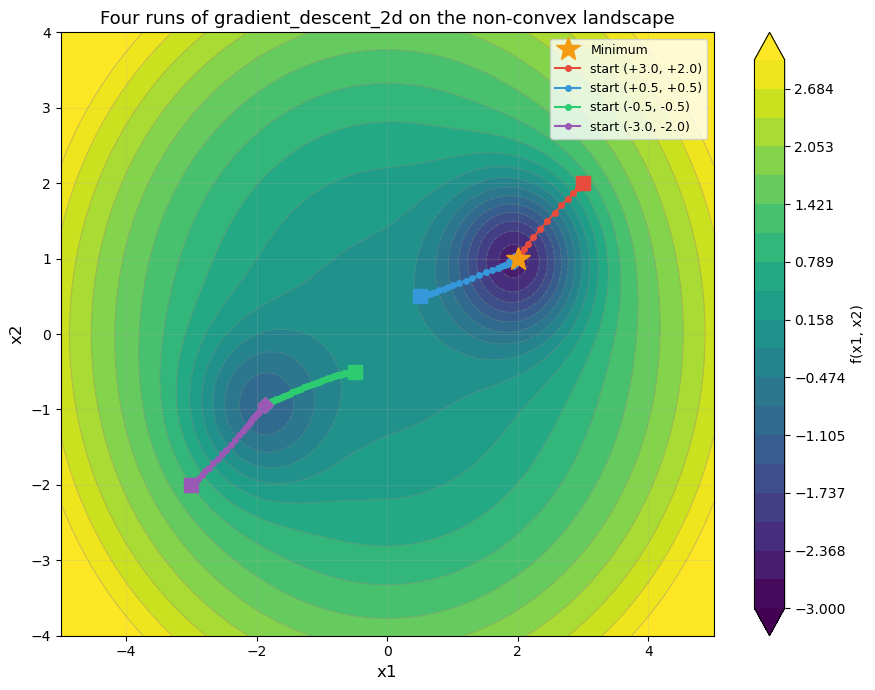

In [50]:
# Visualise the landscape (contour plot — darker = lower f)
plot_contour_2d(f_harder_2d,
                title="Two basins on a shallow bowl",
                xlim=(-5, 5), ylim=(-4, 4),
                minimum=HARDER_2D_GLOBAL_MIN)

# Run YOUR gradient_descent_2d from four starting points.
starts_2d = [
    np.array([ 3.0,  2.0]),  # well inside the right basin
    np.array([ 0.5,  0.5]),  # near the saddle, right-leaning
    np.array([-0.5, -0.5]),  # near the saddle, left-leaning
    np.array([-3.0, -2.0]),  # well inside the left basin
]
paths_2d = [gradient_descent_2d(grad_harder_2d, x0, alpha=0.05, steps=200)
            for x0 in starts_2d]

# Report the endpoints
print(f"{'start':>16s}  →  {'end':>16s}  {'f(end)':>10s}  basin")
print("-" * 65)
for x0, p in zip(starts_2d, paths_2d):
    end = p[-1]
    d_global = np.linalg.norm(end - HARDER_2D_GLOBAL_MIN)
    d_local = np.linalg.norm(end - HARDER_2D_LOCAL_MIN)
    basin = "GLOBAL" if d_global < d_local else "local"
    s = f"({x0[0]:+.2f}, {x0[1]:+.2f})"
    e = f"({end[0]:+.3f}, {end[1]:+.3f})"
    print(f"  {s:>14s}     {e:>16s}  {f_harder_2d(end):+10.3f}  {basin}")

# Overlay all four trajectories on one contour plot
plot_contour_with_path_2d(
    f_harder_2d, paths=paths_2d,
    labels=[f"start ({x[0]:+.1f}, {x[1]:+.1f})" for x in starts_2d],
    title="Four runs of gradient_descent_2d on the non-convex landscape",
    xlim=(-5, 5), ylim=(-4, 4), zlim=(-3, 3),
    minimum=HARDER_2D_GLOBAL_MIN
)

### Non-convex 2D reflection (P9.6, 200 words)

Look at the table and the overlay plot above.

1. **The basin boundary.** Two of your start points were near $(0, 0)$: one slightly positive, one slightly negative. They ended in different basins. What does that tell you about the *boundary* between basins?
2. **No way to know.** If you only had the endpoint $f$-value (without the plot or the landscape formula), would you be able to tell whether you found the global minimum? Why or why not?
3. **A common workaround.** Real ML practitioners often run gradient descent from many random starting points and keep the one with the lowest final loss. This is called **random restart**. Why does it help? When does it stop helping (i.e. what kind of landscape would defeat random restart)?

1. Due to the fact that the two starting points near (0, 0) end up in completely different basins of attraction (one towards the global minimum, one towards the local minimum), it is a good indication that the point (0, 0) is a very sensitive or a boundary point. The starting point of both basins is separated by the boundary between the two basins.
2. No, if I didn't have the plot or the global formula I would not be able to ensure it was the global minimum. The local gradient vanishes at the bottom of any basin and it gives no information on the existence of a deeper basin elsewhere in the parameter space.
3. Random restart also helps, by letting the algorithm restart at many different points on the landscape, thus increasing the chance at least one starting point is in the basin of attraction corresponding to the global minimum. But, on landscapes that resemble a golf course, with a global minimum that is very small and quite narrow, random restart does not work out. The probability of the random landing being exactly in that very small basin is very small.
> **Connection to the Credit tier.** Random restart is exactly the strategy used in C1.1 Search Extensions for hill climbing: same fix, different problem. The pattern "local algorithms + multiple restarts" appears across AI.

---

## Part 7: Check your understanding

Run the quiz below.

In [51]:
from jupyterquiz import display_quiz

p9_quiz = [
    {
        "question": "What does the gradient \\(\\nabla f(\\mathbf{x})\\) point toward?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "The direction of steepest ascent.", "correct": True,
             "feedback": "Yes — and gradient descent moves in the opposite direction to minimise."},
            {"answer": "The minimum of the function.", "correct": False,
             "feedback": "No — the gradient points uphill. The minimum is reached by walking opposite to the gradient."},
            {"answer": "The origin.", "correct": False,
             "feedback": "No — the gradient depends on f and on where you are, not on the origin."},
            {"answer": "Always the global minimum.", "correct": False,
             "feedback": "No — even when followed, the negative gradient leads to a *local* minimum, not necessarily the global one."}
        ]
    },
    {
        "question": "Gradient descent on a non-convex function from a single starting point gives you:",
        "type": "multiple_choice",
        "answers": [
            {"answer": "A local minimum, which may or may not be the global minimum.", "correct": True,
             "feedback": "Right — local descent only guarantees a local minimum. Whether it is global depends on where you started."},
            {"answer": "The global minimum, always.", "correct": False,
             "feedback": "No — Parts 4 and 6 showed that different starts give different end points."},
            {"answer": "An infinite loop.", "correct": False,
             "feedback": "No — the gradient is zero at any minimum (local or global), so the algorithm stops."},
            {"answer": "Failure to converge.", "correct": False,
             "feedback": "Failure to converge happens with too-large learning rates, not from non-convexity per se."}
        ]
    },
    {
        "question": "If you double the learning rate \\(\\alpha\\), what is likely to happen on a quadratic loss?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Steps get bigger; convergence may be faster, or it may overshoot.", "correct": True,
             "feedback": "Yes — Part 3 showed this. Bigger \\(\\alpha\\) is a knife-edge: faster if stable, divergent if too large."},
            {"answer": "The function f changes.", "correct": False,
             "feedback": "No — \\(\\alpha\\) is purely the step size, not part of f."},
            {"answer": "The gradient changes.", "correct": False,
             "feedback": "No — the gradient depends only on f and on the current point."},
            {"answer": "Nothing changes.", "correct": False,
             "feedback": "No — Part 3 shows that the trajectory depends strongly on \\(\\alpha\\)."}
        ]
    },
    {
        "question": "Going from 1D to 2D, the update rule becomes \\(\\mathbf{x} \\leftarrow \\mathbf{x} - \\alpha \\nabla f(\\mathbf{x})\\). What is \\(\\nabla f\\)?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "A vector of partial derivatives, one per input dimension.", "correct": True,
             "feedback": "Right — for 2D, \\(\\nabla f = [\\partial f / \\partial x_1, \\partial f / \\partial x_2]\\)."},
            {"answer": "A single scalar slope.", "correct": False,
             "feedback": "That is the 1D derivative. In 2D you get a vector with one component per input dimension."},
            {"answer": "A matrix.", "correct": False,
             "feedback": "Second derivatives form a matrix (the Hessian). The gradient is the *vector* of first partial derivatives."},
            {"answer": "The function value at the minimum.", "correct": False,
             "feedback": "The gradient is a derivative, not a value of f."}
        ]
    }
]

display_quiz(p9_quiz, shuffle_answers=True)

<IPython.core.display.Javascript object>

---

## Part 9: Record Your Results

Fill in the table below with your results from across the notebook:

| Metric | Value |
|--------|-------|
| Hand-trace 1D: $w$ after 5 steps (YOUR personalised $c$, $w_0$, $\alpha=0.1$) |-1.9830 |
| Part 3: $\alpha=0.01$, $w$ after 30 steps | 2.1819 |
| Part 3: $\alpha=0.1$, $w$ after 30 steps | 0.0049 |
| Part 3: $\alpha=0.95$, divergent? (yes / no) | No |
| Part 4: which starts hit the global minimum? (list w-values) | -1.0, 0.0 |
| Part 4: which starts hit a local minimum? (list w-values) | 5.0 |
| Hand-trace 2D: gradient at $(-3, -2)$ | (-10.0, -6.0) |
| Part 5: 2D bowl convergence (final $x$ after 40 steps, $\alpha=0.1$) | (2.0, 1.0) |
| Part 6: number of starting points that hit GLOBAL basin | 2 |
| Part 6: number of starting points that hit local basin | 2 |

---

### P9.7: Reflection: "Who labelled the data, and under what conditions?" (150–250 words)

Gradient descent is the optimisation engine inside modern ML. But optimisation operates on a *loss function*, and a loss function operates on *data*. Where does the data come from?

- ImageNet contains over 14 million images, each labelled by hand. Most labels were provided by workers on Amazon Mechanical Turk, often paid fractions of a cent per image.
- The 2012 AlexNet breakthrough was as much about data infrastructure as it was about the gradient-descent algorithm.
- Who benefits from these labels? Who bears the cost?
- What does this mean for how we build and evaluate AI systems today?

**Write your response in the cell below — it stays in this notebook.** You do not upload it as a separate file.

---

**Your response:**

Recent machine learning methods such as gradient descent have been successful when applied to very large collections of data. Although such advances as AlexNet may appear to be algorithmic advances or hardware feats, they would never have been possible without the foundational data infrastructure, ImageNet. Thousands of tenuous gig workers were hired to annotate millions of files, in this case on Amazon Mechanical Turk, and paid very little, typically a few cents per image, to perform the task. This is an incredible imbalance in the AI world: the financial and reputational returns go to the big tech firms and the human toll – to poorly remunerated, repetitive and often mentally challenging work – goes to an unseen, global labour force.

This unseen work affects our building and evaluation of AI systems today in principle. Optimization is not just a mathematical manipulation binary operation set in a vacuum. The loss function is in essence the manifestation of the biases, fatigue, and systemic inequities for the workers who must label data at breakneck speeds to make a living. This supply chain needs to be transparent to ensure responsible AI use. With labeled data as the objective and neutral ground-truth, as the ground truth, we run the risk of washing away systemic biases, and fail to mention the exploitative work practices that rendered our gradient descent algorithms functional in the first place.

---

## Submission Checklist

- [ ] **P9.1:** Hand computation of 5 gradient-descent steps in 1D (photographed)
- [ ] **P9.2:** `gradient_descent` (1D) implemented and matches hand-trace values
- [ ] **P9.3:** Three learning rates compared on $f(w) = w^2$; analysis questions answered
- [ ] **P9.4:** Local-minima reflection written (Part 4)
- [ ] **P9.5:** 2D gradient step hand-computed (photographed) **and** `gradient_descent_2d` implemented, converging on the bowl to (2, 1)
- [ ] **P9.6:** Non-convex reflection written (Part 6, 200 words)
- [ ] **Part 7:** Quiz attempted
- [ ] **P9.7:** Results table filled in + 150–250 word reflection on data labelling (written in this notebook)
- [ ] Milestone discussion booked with tutor

**Uploading to OnTrack.** Submit **two things**: (1) this completed notebook, and (2) a **single** file (photo or PDF) containing **both** your hand traces — P9.1 (1D) and P9.5 (2D). Combine both photos into one PDF or image. Your written reflections stay *inside this notebook* — OnTrack allows only one extra file besides the notebook, and that file is your combined hand traces.

---

> **Caution: AI use at PASS level.**
> AI tools are **discouraged** for implementation tasks. You may use AI for *explanation*, but not to generate code or reflections. Cite all AI use.

---

*FIT1061 Pass Task 9: Gradient Descent (1D + 2D, non-convex landscapes)*